# 01 · Phân Tích Khám Phá Dữ Liệu Đa Tập (EDA — ULB · IEEE-CIS · PaySim)
**Dự án:** SentinelRisk AI — Real-Time Fraud & Transaction Risk Detection Platform  
**Mục tiêu:** Khảo sát cấu trúc, mức độ mất cân bằng cực đoan, phân bố số tiền, biến động gian lận theo thời gian (Concept Drift) và tỷ lệ dữ liệu khuyết trên cả 3 tập dữ liệu chuẩn mực của luận văn (`ULB CreditCard`, `IEEE-CIS`, `PaySim`), từ đó làm cơ sở khoa học cho:
1. Chọn **PR-AUC** (thay vì Accuracy) làm thước đo chính.
2. Bắt buộc áp dụng **Time-Based Chronological Split** chống Data Leakage (`ML-DL-02`).
3. Thiết kế 3 nhóm đặc trưng hành vi (`Velocity`, `Behavioural`, `Novelty`) ở Notebook `02`.

> Tương thích chạy độc lập trên cả **Local (`../data/`)** và **Kaggle (`/kaggle/input/ieee-fraud-detection`)**.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")

# Publication-grade chart style (clean light canvas for thesis PDF, GitHub & Kaggle)
PALETTE = {
    "blue": "#0284c7",
    "cyan": "#0891b2",
    "red": "#e11d48",
    "green": "#059669",
    "purple": "#6d28d9",
    "amber": "#d97706",
    "slate": "#475569",
    "muted": "#94a3b8",
}
plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#e2e8f0",
    "figure.dpi": 120,
})

# Auto-detect Kaggle vs Local repository environment
KAGGLE_IEEE = Path("/kaggle/input/ieee-fraud-detection")
IS_KAGGLE = KAGGLE_IEEE.exists()
if IS_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    WORK_DIR = Path("/kaggle/working/sentinel_cache")
else:
    DATA_ROOT = Path("../data") if Path("../data").exists() else Path("data")
    WORK_DIR = DATA_ROOT / "features" / "ieee_cis"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment : {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")
print(f"DATA_ROOT   : {DATA_ROOT}")
print(f"CACHE_DIR   : {WORK_DIR}")

Environment : LOCAL
DATA_ROOT   : ..\data
CACHE_DIR   : ..\data\features\ieee_cis


## 1. Tổng Quan 3 Tập Dữ Liệu Thực Tế

In [2]:
import pyarrow.parquet as pq

datasets_summary = []

# 1) IEEE-CIS (Primary Thesis & Kaggle Benchmark Dataset)
if IS_KAGGLE:
    ieee_txn = pd.read_csv(
        KAGGLE_IEEE / "train_transaction.csv",
        usecols=["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD", "card1", "card4", "card6", "addr1", "P_emaildomain"],
    )
    ieee_id = pd.read_csv(KAGGLE_IEEE / "train_identity.csv", usecols=["TransactionID", "DeviceType", "DeviceInfo"])
    df_ieee = ieee_txn.merge(ieee_id, on="TransactionID", how="left").sort_values("TransactionDT").reset_index(drop=True)
    ieee_total_cols = 434
else:
    pdir = DATA_ROOT / "processed" / "ieee_cis"
    cols_eda = ["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD", "card1", "card4", "card6", "addr1", "P_emaildomain", "DeviceType", "DeviceInfo"]
    df_ieee = pd.concat([
        pd.read_parquet(pdir / f"{s}_merged.parquet", columns=cols_eda)
        for s in ("train", "val", "test")
    ], ignore_index=True)
    ieee_total_cols = pq.ParquetFile(pdir / "train_merged.parquet").metadata.num_columns

n_ieee_f = int(df_ieee["isFraud"].sum())
datasets_summary.append({
    "Dataset": "IEEE-CIS Fraud Detection",
    "Rows": len(df_ieee),
    "Columns": ieee_total_cols,
    "Fraud Count": n_ieee_f,
    "Fraud Rate (%)": round(n_ieee_f / len(df_ieee) * 100, 3),
    "Imbalance (Legit:Fraud)": f"{int((len(df_ieee)-n_ieee_f)/max(n_ieee_f,1))}:1",
    "Role in Platform": "Main Model, Ablation & SHAP (E06–E16)",
})

# 2) ULB CreditCard (284K rows)
df_ulb = None
ulb_dir = DATA_ROOT / "processed" / "ubl_creditcard"
if ulb_dir.exists() and (ulb_dir / "train.parquet").exists():
    df_ulb = pd.concat([pd.read_parquet(ulb_dir / f"{s}.parquet") for s in ("train", "val", "test")], ignore_index=True)
    n_ulb_f = int(df_ulb["isFraud"].sum())
    datasets_summary.append({
        "Dataset": "ULB CreditCard (2013)",
        "Rows": len(df_ulb),
        "Columns": df_ulb.shape[1],
        "Fraud Count": n_ulb_f,
        "Fraud Rate (%)": round(n_ulb_f / len(df_ulb) * 100, 3),
        "Imbalance (Legit:Fraud)": f"{int((len(df_ulb)-n_ulb_f)/max(n_ulb_f,1))}:1",
        "Role in Platform": "Baseline & Extreme Imbalance (E01–E05)",
    })

# 3) PaySim (2.77M TRANSFER + CASH_OUT rows)
df_ps = None
ps_dir = DATA_ROOT / "processed" / "paysim"
if ps_dir.exists() and (ps_dir / "train.parquet").exists():
    ps_cols = ["step", "amount", "isFraud", "balance_diff_orig", "dest_empty_before", "is_transfer"]
    df_ps = pd.concat([pd.read_parquet(ps_dir / f"{s}.parquet", columns=ps_cols) for s in ("train", "val", "test")], ignore_index=True)
    n_ps_f = int(df_ps["isFraud"].sum())
    datasets_summary.append({
        "Dataset": "PaySim (TRANSFER/CASH_OUT)",
        "Rows": len(df_ps),
        "Columns": 13,
        "Fraud Count": n_ps_f,
        "Fraud Rate (%)": round(n_ps_f / len(df_ps) * 100, 3),
        "Imbalance (Legit:Fraud)": f"{int((len(df_ps)-n_ps_f)/max(n_ps_f,1))}:1",
        "Role in Platform": "Real-time Streaming & Demo Simulator",
    })

summary_df = pd.DataFrame(datasets_summary)
display(summary_df)
print(f"\nTổng quy mô dữ liệu thực nghiệm: {summary_df['Rows'].sum():,} giao dịch.")

,Dataset,Rows,Columns,Fraud Count,Fraud Rate (%),Imbalance (Legit:Fraud),Role in Platform
0,IEEE-CIS Fraud Detection,590540,435,20663,3.499,27:1,"Main Model, Ablation & SHAP (E06–E16)"
1,ULB CreditCard (2013),284807,31,492,0.173,577:1,Baseline & Extreme Imbalance (E01–E05)
2,PaySim (TRANSFER/CASH_OUT),2770409,13,8213,0.296,336:1,Real-time Streaming & Demo Simulator



Tổng quy mô dữ liệu thực nghiệm: 3,645,756 giao dịch.


## 2. Mức Độ Mất Cân Bằng Lớp & Biến Động Gian Lận Theo Thời Gian (Temporal Drift)

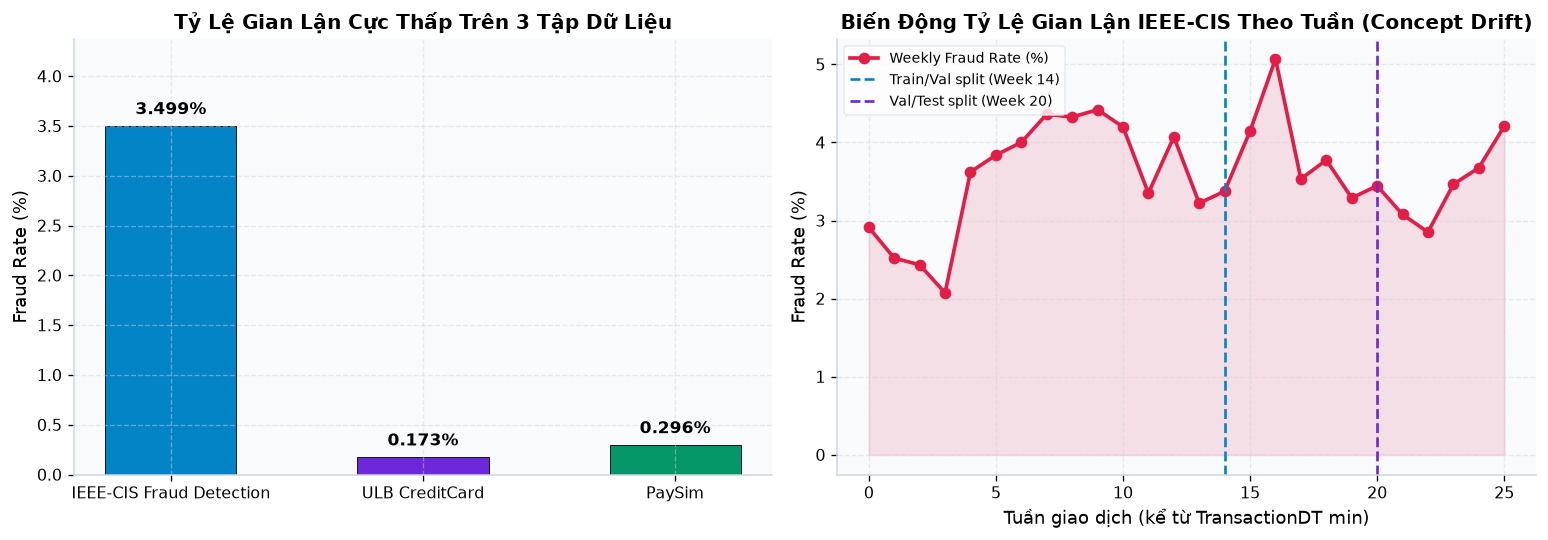

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Panel A: Fraud Rate comparison across datasets
ax = axes[0]
names = [r["Dataset"].split(" (")[0] for r in datasets_summary]
rates = [r["Fraud Rate (%)"] for r in datasets_summary]
colors = [PALETTE["blue"], PALETTE["purple"], PALETTE["green"]][:len(names)]
bars = ax.bar(names, rates, color=colors, width=0.52, edgecolor="#0f172a", linewidth=0.6)
for b, r in zip(bars, rates):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.08, f"{r:.3f}%", ha="center", va="bottom", fontweight="bold", fontsize=10)
ax.set_title("Tỷ Lệ Gian Lận Cực Thấp Trên 3 Tập Dữ Liệu")
ax.set_ylabel("Fraud Rate (%)")
ax.set_ylim(0, max(rates) * 1.25)

# Panel B: IEEE-CIS Fraud Rate by Week (TransactionDT) with 60/20/20 split boundaries
ax = axes[1]
week = ((df_ieee["TransactionDT"] - df_ieee["TransactionDT"].min()) // (7 * 86400)).astype(int)
weekly = df_ieee.assign(week=week).groupby("week")["isFraud"].agg(["count", "mean"])
ax.plot(weekly.index, weekly["mean"] * 100, marker="o", lw=2.2, color=PALETTE["red"], label="Weekly Fraud Rate (%)")

n_all = len(df_ieee)
w_tr_end = int(week.iloc[int(n_all * 0.60)])
w_va_end = int(week.iloc[int(n_all * 0.80)])
ax.axvline(w_tr_end, color=PALETTE["blue"], ls="--", lw=1.6, label=f"Train/Val split (Week {w_tr_end})")
ax.axvline(w_va_end, color=PALETTE["purple"], ls="--", lw=1.6, label=f"Val/Test split (Week {w_va_end})")
ax.fill_between(weekly.index, weekly["mean"] * 100, alpha=0.12, color=PALETTE["red"])
ax.set_title("Biến Động Tỷ Lệ Gian Lận IEEE-CIS Theo Tuần (Concept Drift)")
ax.set_xlabel("Tuần giao dịch (kể từ TransactionDT min)")
ax.set_ylabel("Fraud Rate (%)")
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

## 3. Phân Bố Số Tiền Giao Dịch & Tín Hiệu Nghiệp Vụ Trên IEEE-CIS

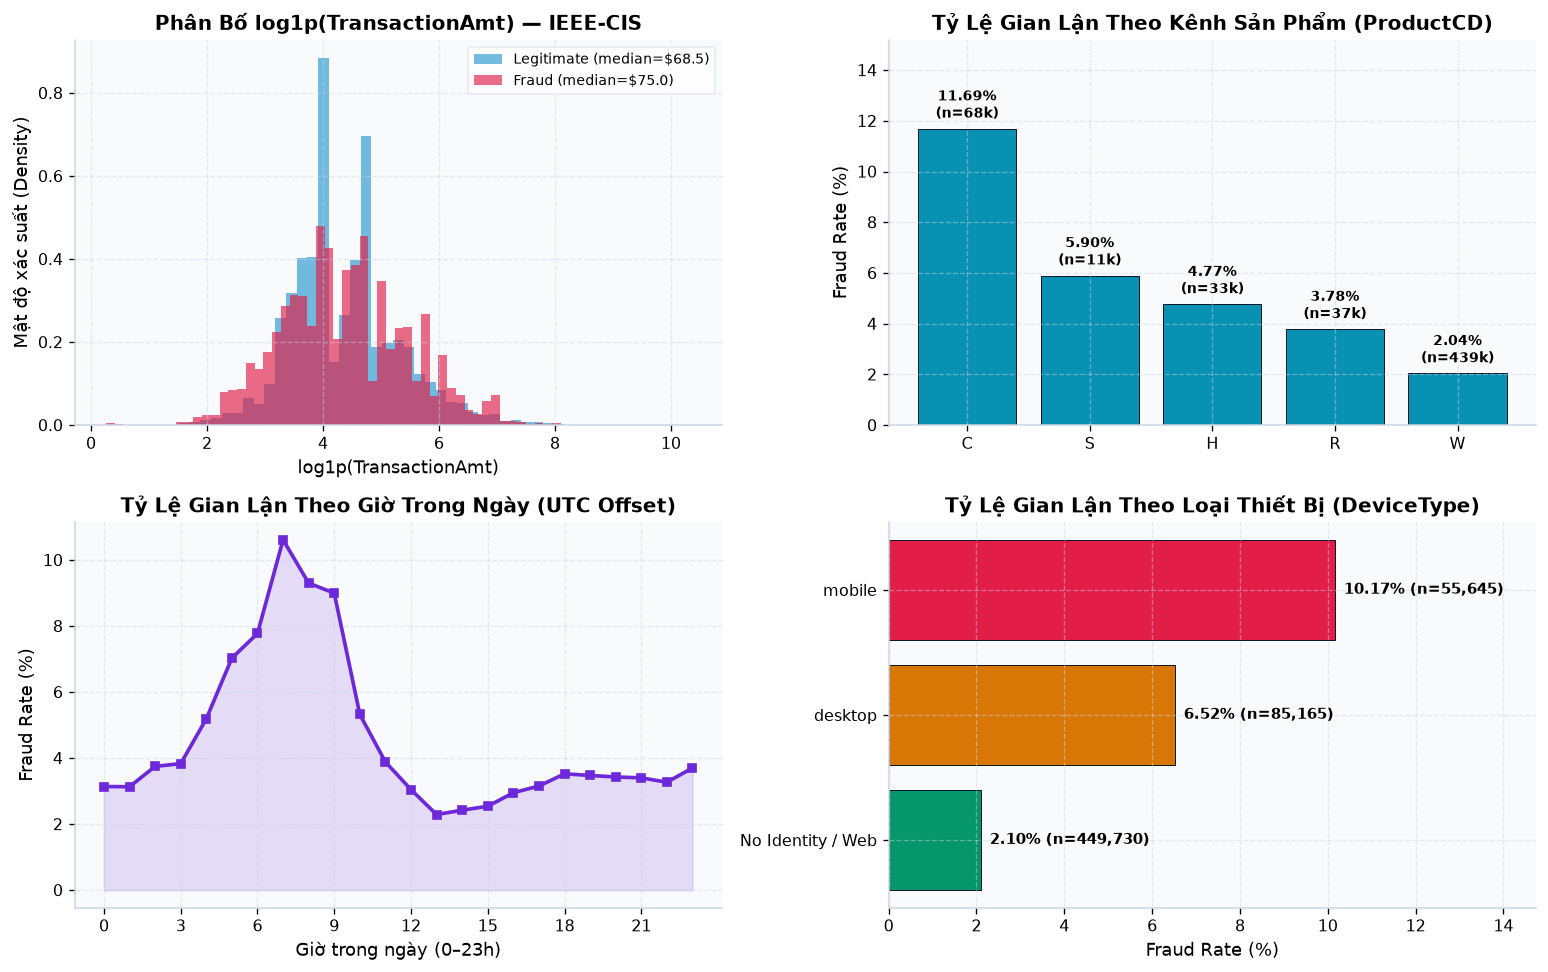

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))

# Panel 1: Log Amount distribution (IEEE-CIS)
ax = axes[0, 0]
amt_legit = np.log1p(df_ieee.loc[df_ieee["isFraud"] == 0, "TransactionAmt"])
amt_fraud = np.log1p(df_ieee.loc[df_ieee["isFraud"] == 1, "TransactionAmt"])
ax.hist(amt_legit, bins=55, density=True, alpha=0.55, color=PALETTE["blue"], label=f"Legitimate (median=${df_ieee.loc[df_ieee['isFraud']==0,'TransactionAmt'].median():.1f})")
ax.hist(amt_fraud, bins=55, density=True, alpha=0.65, color=PALETTE["red"], label=f"Fraud (median=${df_ieee.loc[df_ieee['isFraud']==1,'TransactionAmt'].median():.1f})")
ax.set_title("Phân Bố log1p(TransactionAmt) — IEEE-CIS")
ax.set_xlabel("log1p(TransactionAmt)")
ax.set_ylabel("Mật độ xác suất (Density)")
ax.legend(fontsize=8.5)

# Panel 2: Fraud Rate by ProductCD
ax = axes[0, 1]
prod_stats = df_ieee.groupby("ProductCD", observed=False)["isFraud"].agg(["count", "mean"]).sort_values("mean", ascending=False)
bars = ax.bar(prod_stats.index.astype(str), prod_stats["mean"] * 100, color=PALETTE["cyan"], edgecolor="#0f172a", linewidth=0.6)
for b, (_, row) in zip(bars, prod_stats.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.25, f"{row['mean']*100:.2f}%\n(n={int(row['count'])//1000}k)", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_title("Tỷ Lệ Gian Lận Theo Kênh Sản Phẩm (ProductCD)")
ax.set_ylabel("Fraud Rate (%)")
ax.set_ylim(0, prod_stats["mean"].max() * 130)

# Panel 3: Fraud Rate by Hour of Day
ax = axes[1, 0]
hour = ((df_ieee["TransactionDT"] // 3600) % 24).astype(int)
hr_stats = df_ieee.assign(hour=hour).groupby("hour")["isFraud"].agg(["count", "mean"])
ax.plot(hr_stats.index, hr_stats["mean"] * 100, marker="s", ms=4.5, lw=2.2, color=PALETTE["purple"])
ax.fill_between(hr_stats.index, hr_stats["mean"] * 100, alpha=0.14, color=PALETTE["purple"])
ax.set_title("Tỷ Lệ Gian Lận Theo Giờ Trong Ngày (UTC Offset)")
ax.set_xlabel("Giờ trong ngày (0–23h)")
ax.set_ylabel("Fraud Rate (%)")
ax.set_xticks(range(0, 24, 3))

# Panel 4: Fraud Rate by DeviceType & Card Network
ax = axes[1, 1]
dev_s = df_ieee["DeviceType"].astype("string").fillna("No Identity / Web")
dev_stats = df_ieee.assign(dev=dev_s).groupby("dev")["isFraud"].agg(["count", "mean"]).sort_values("mean", ascending=True)
bars = ax.barh(dev_stats.index, dev_stats["mean"] * 100, color=[PALETTE["green"], PALETTE["amber"], PALETTE["red"]][:len(dev_stats)], edgecolor="#0f172a", linewidth=0.6)
for b, (_, row) in zip(bars, dev_stats.iterrows()):
    ax.text(b.get_width() + 0.2, b.get_y() + b.get_height()/2, f"{row['mean']*100:.2f}% (n={int(row['count']):,})", va="center", fontsize=8.8, fontweight="bold")
ax.set_title("Tỷ Lệ Gian Lận Theo Loại Thiết Bị (DeviceType)")
ax.set_xlabel("Fraud Rate (%)")
ax.set_xlim(0, dev_stats["mean"].max() * 145)

plt.tight_layout()
plt.show()

## 4. Khảo Sát Dữ Liệu Khuyết (IEEE-CIS) & Bất Thường Số Dư (PaySim)

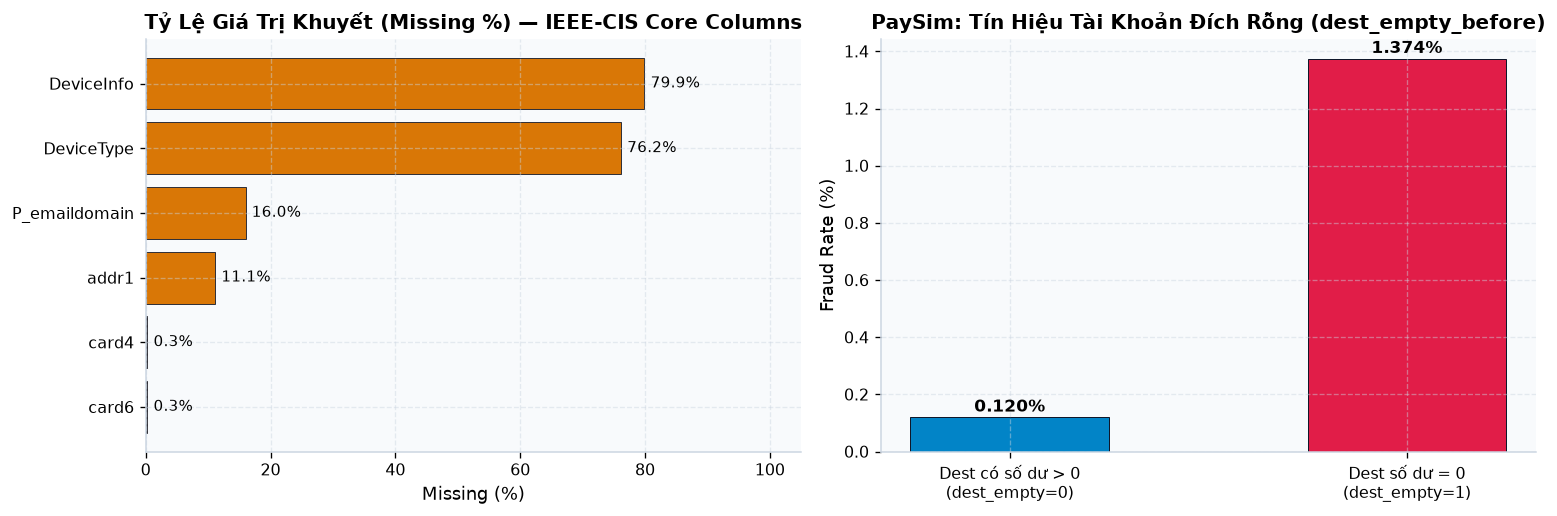

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

# Missingness in core IEEE-CIS columns
ax = axes[0]
miss_pct = (df_ieee.isna().mean() * 100).sort_values(ascending=True)
miss_nz = miss_pct[miss_pct > 0]
bars = ax.barh(miss_nz.index, miss_nz.values, color=PALETTE["amber"], edgecolor="#0f172a", linewidth=0.5)
for b, v in zip(bars, miss_nz.values):
    ax.text(v + 1.0, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center", fontsize=8.8)
ax.set_title("Tỷ Lệ Giá Trị Khuyết (Missing %) — IEEE-CIS Core Columns")
ax.set_xlabel("Missing (%)")
ax.set_xlim(0, 105)

# PaySim balance anomaly signal (or IEEE-CIS card4 if PaySim not attached on Kaggle)
ax = axes[1]
if df_ps is not None:
    ps_sig = df_ps.groupby("dest_empty_before")["isFraud"].agg(["count", "mean"])
    labels = ["Dest có số dư > 0\n(dest_empty=0)", "Dest số dư = 0\n(dest_empty=1)"]
    bars = ax.bar(labels, ps_sig["mean"] * 100, color=[PALETTE["blue"], PALETTE["red"]], width=0.5, edgecolor="#0f172a", linewidth=0.6)
    for b, v in zip(bars, ps_sig["mean"] * 100):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.3f}%", ha="center", fontweight="bold")
    ax.set_title("PaySim: Tín Hiệu Tài Khoản Đích Rỗng (dest_empty_before)")
    ax.set_ylabel("Fraud Rate (%)")
else:
    c4 = df_ieee.groupby("card4", observed=False)["isFraud"].mean().sort_values(ascending=False) * 100
    ax.bar(c4.index.astype(str), c4.values, color=PALETTE["blue"])
    ax.set_title("IEEE-CIS: Fraud Rate theo mạng thẻ (card4)")
    ax.set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

## 5. Kết Luận EDA & Hàm Ý Thiết Kế Hệ Thống
1. **Mất cân bằng cực đoan (`0.17%` trên ULB, `3.50%` trên IEEE-CIS, `0.30%` trên PaySim):** Một mô hình dự đoán toàn bộ `0` vẫn đạt Accuracy > 96.5%–99.8%. Do đó **PR-AUC** và **Recall@FPR≤1%** cùng **Expected Business Cost** là các tiêu chí bắt buộc.
2. **Tồn tại Concept Drift theo thời gian:** Tỷ lệ gian lận biến thiên mạnh giữa các tuần trên IEEE-CIS → nghiêm cấm chia ngẫu nhiên (`train_test_split`), bắt buộc chia theo trình tự thời gian **60/20/20** (`ML-DL-02`).
3. **Tín hiệu hành vi & thiết bị rất rõ rệt:** `ProductCD = C` có tỷ lệ gian lận vượt trội (>11%), `mobile` cao hơn rõ rệt so với giao dịch không có identity, và biến thiên mạnh theo khung giờ → định hướng trực tiếp cho 3 nhóm đặc trưng **Velocity**, **Behavioural**, **Novelty** ở Notebook `02_feature_engineering.ipynb`.
4. **Dữ liệu khuyết mang thông tin (`DeviceType`, `DeviceInfo` khuyết >75%):** Mô hình cây tăng cường (XGBoost `hist`) xử lý giá trị khuyết tự nhiên hiệu quả hơn nhiều so với mô hình tuyến tính.